# Exploring Winter Climate Patterns in Bozeman, MT with K-Means Clustering and Random Forest Classification

## Abstract

This project uses one unsupervised and one supervised machine learning technique to explore winter weather patterns at the Bozeman Gallatin Field Airport weather station (NOAA GHCN-Daily, station USW00024132) using daily data from January 1, 2000 to June 1, 2026.

I aggregated five daily weather variables (precipitation, maximum temperature, minimum temperature, snowfall, and snow depth) into winter seasons (December through March). This produced 27 winters, from 1999–2000 through 2025–2026. The 1999–2000 winter is partial (January–March only), because the record starts January 1, 2000.

**Unsupervised model:** K-Means clustering grouped winters with similar weather into three clusters.

**Supervised model:** a Random Forest classifier was trained to reproduce the K-Means cluster assignments from the same five features. Because the labels come from the same features, this step measures how separable the clusters are and which features define them. It does not forecast future winters.

**Main finding:** the snowfall and snow depth records at this station are mostly missing (about 88% and 84% of days), and those gaps were filled with zero. The clusters are strongly shaped by this missing data, so they should be read as a lesson in data quality more than as true climate regimes. The Limitations section explains this in detail.

## Contents

1. Abstract
2. Introduction
3. Methodology
   - Data Collection and Preprocessing
   - Unsupervised Learning: K-Means Clustering
   - Supervised Learning: Random Forest Classification
4. Code and Outputs
5. Results
   - K-Means Clustering
   - Random Forest Classification
6. Limitations and Known Issues
7. Next Steps
8. References

## Introduction

Winter conditions in southwest Montana matter for snowpack, spring runoff, water supply, and the ski season. Machine learning has been applied to drought and climate prediction in other regions [2], and clustering is a common way to look for recurring weather patterns in historical records.

This project asks a simpler, exploratory question: using 26 years of daily records from the Bozeman airport weather station, do winters fall into distinct groups, and which weather variables separate those groups?

## Methodology

### Data Collection and Preprocessing

Daily weather data came from NOAA's Global Historical Climatology Network-Daily (GHCN-Daily) database for the Bozeman Gallatin Field Airport station (USW00024132), from January 1, 2000 to June 1, 2026 [1]. Five variables were used: precipitation (PRCP), maximum temperature (TMAX), minimum temperature (TMIN), snowfall (SNOW), and snow depth (SNWD).

Each December was assigned to the following winter (for example, December 2000 belongs to winter 2000–2001), and only December through March were kept. This produced 27 winters, from 1999–2000 (partial: January–March only) through 2025–2026.

For each winter, PRCP and SNOW were summed to get seasonal totals, and SNWD, TMAX, and TMIN were averaged. Snowfall was missing on 8,198 of 9,282 daily records and snow depth on 7,842. Missing values were treated as zero during aggregation. As the results show, this choice has a large effect on the clusters.

### Unsupervised Learning: K-Means Clustering

The five winter features (PRCP_total, SNOW_total, SNWD_avg, TMAX_avg, TMIN_avg) were standardized with StandardScaler so each feature carries equal weight. K-Means was run for k = 2 to 5, and the elbow method and silhouette scores were used to choose k. Principal Component Analysis (PCA) was used only to visualize the clusters in two dimensions.

### Supervised Learning: Random Forest Classification

A Random Forest classifier (100 trees, maximum depth 5, minimum samples per split 3) was trained to predict each winter's K-Means cluster from the same five standardized features. With only 27 winters, a single train/test split would leave very few test examples, so performance was estimated with 5-fold cross-validation, which tests every winter exactly once. Metrics include mean accuracy across folds, a classification report, a confusion matrix, and feature importances (mean decrease in impurity).

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

## Code and Outputs

### Loading and Cleaning the Data

In [ ]:
# Load the daily weather data.
# Source: NOAA GHCN-Daily, Bozeman Gallatin Field Airport (USW00024132), 2000-01-01 to 2026-06-01.
# Download from NOAA Climate Data Online (https://www.ncdc.noaa.gov/cdo-web/) and save as data/Drought_Data.csv.
# (If running in Google Colab, mount Drive and point this path to your copy instead.)
df = pd.read_csv('data/Drought_Data.csv')

In [ ]:
print("Original data shape:", df.shape)
print("\nFirst few rows:")
print(df.head())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())

Original data shape: (9282, 8)

First few rows:
       STATION                                   NAME        DATE  PRCP  SNOW  \
0  USW00024132  BOZEMAN GALLATIN FIELD AIRPORT, MT US  2000-01-01  0.00   NaN   
1  USW00024132  BOZEMAN GALLATIN FIELD AIRPORT, MT US  2000-01-02  0.04   NaN   
2  USW00024132  BOZEMAN GALLATIN FIELD AIRPORT, MT US  2000-01-03  0.00   NaN   
3  USW00024132  BOZEMAN GALLATIN FIELD AIRPORT, MT US  2000-01-04  0.00   NaN   
4  USW00024132  BOZEMAN GALLATIN FIELD AIRPORT, MT US  2000-01-05  0.00   NaN   

   SNWD  TMAX  TMIN  
0   NaN    40  20.0  
1   NaN    30  15.0  
2   NaN    30  13.0  
3   NaN    42  20.0  
4   NaN    34  21.0  

Data types:
STATION     object
NAME        object
DATE        object
PRCP       float64
SNOW       float64
SNWD       float64
TMAX         int64
TMIN       float64
dtype: object

Missing values:
STATION       0
NAME          0
DATE          0
PRCP          5
SNOW       8198
SNWD       7842
TMAX          0
TMIN          1
dtype: in

In [ ]:
# Convert DATE to datetime format FIRST
df['DATE'] = pd.to_datetime(df['DATE'])

# NOW extract month and year
df['Month'] = df['DATE'].dt.month
df['Year'] = df['DATE'].dt.year

In [ ]:
# CREATE WINTER YEAR VARIABLE

df['Month'] = df['DATE'].dt.month
df['Year'] = df['DATE'].dt.year

# Create winter_year variable as a string like "2000-2001"
df['Winter_Year'] = df['Year'].copy()

# If December, it belongs to the NEXT year's winter (e.g., Dec 2000 → 2000-2001)
# If Jan, Feb, Mar, it belongs to that year's winter (e.g., Jan 2001 → 2000-2001)
df.loc[df['Month'] == 12, 'Winter_Year'] = df['Year']
df.loc[df['Month'].isin([1, 2, 3]), 'Winter_Year'] = df['Year'] - 1

# Create string format "2000-2001"
df['Winter_Year_Label'] = df['Winter_Year'].astype(str) + '-' + (df['Winter_Year'] + 1).astype(str)

# Filter for winter months only (Dec, Jan, Feb, Mar)
winter_months = [12, 1, 2, 3]
df_winter = df[df['Month'].isin(winter_months)].copy()

print("\nWinter data shape:", df_winter.shape)
print("Sample winters:")
print(df_winter[['DATE', 'Month', 'Year', 'Winter_Year', 'Winter_Year_Label']].head(10))




Winter data shape: (3122, 12)
Sample winters:
        DATE  Month  Year  Winter_Year Winter_Year_Label
0 2000-01-01      1  2000         1999         1999-2000
1 2000-01-02      1  2000         1999         1999-2000
2 2000-01-03      1  2000         1999         1999-2000
3 2000-01-04      1  2000         1999         1999-2000
4 2000-01-05      1  2000         1999         1999-2000
5 2000-01-06      1  2000         1999         1999-2000
6 2000-01-07      1  2000         1999         1999-2000
7 2000-01-08      1  2000         1999         1999-2000
8 2000-01-09      1  2000         1999         1999-2000
9 2000-01-10      1  2000         1999         1999-2000


In [ ]:
winter_agg = df_winter.groupby('Winter_Year_Label').agg({
    'PRCP': 'sum',
    'SNOW': 'sum',
    'SNWD': 'mean',
    'TMAX': 'mean',
    'TMIN': 'mean'
}).reset_index()

winter_agg.columns = ['Winter_Year', 'PRCP_total', 'SNOW_total', 'SNWD_avg', 'TMAX_avg', 'TMIN_avg']

In [ ]:
# After aggregating winters, immediately fill missing SNWD
winter_agg['SNWD_avg'] = winter_agg['SNWD_avg'].fillna(0)

print(f"Winter data shape: {winter_agg.shape}")  # Should be (27, X)

# THEN run K-Means and the rest

Winter data shape: (27, 6)


### Model 1: K-Means Clustering

Standardize the five winter features, compare k = 2 to 5 with the elbow method and silhouette scores, then fit K-Means with k = 3.

Features ready for K-Means:
Shape: (27, 5)
Features: ['PRCP_total', 'SNOW_total', 'SNWD_avg', 'TMAX_avg', 'TMIN_avg']


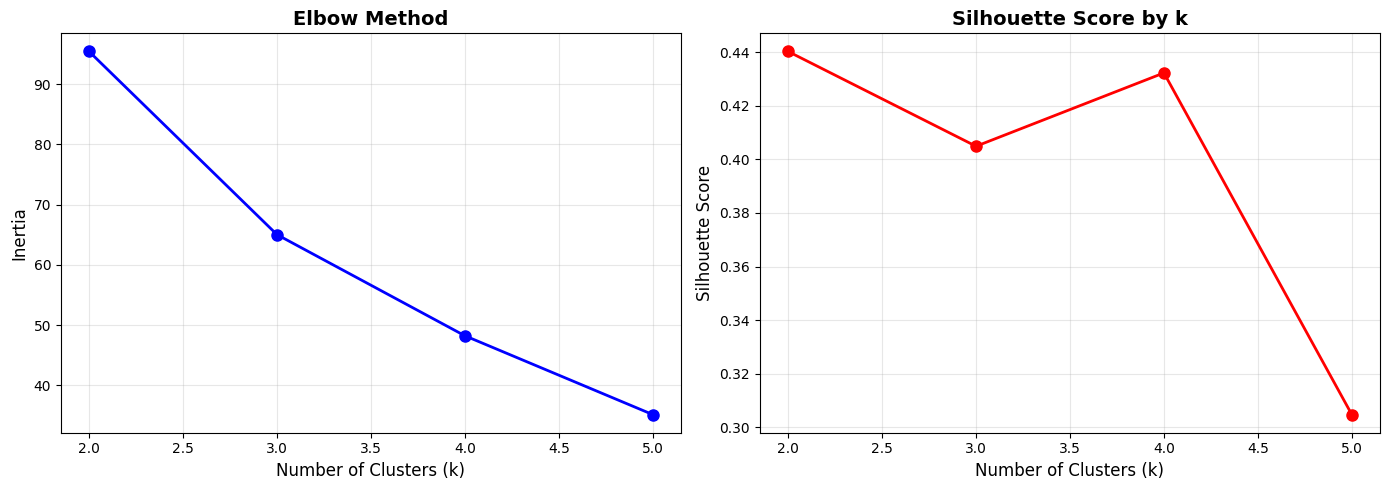


Silhouette Scores:
k=2: 0.4402
k=3: 0.4049
k=4: 0.4322
k=5: 0.3048

K-Means with k=3 fitted!

Cluster assignments by winter:
   Winter_Year  Cluster  PRCP_total  SNOW_total   TMAX_avg
0    1999-2000        1        1.95         0.0  42.461538
1    2000-2001        0        1.43         0.0  30.628099
2    2001-2002        0        1.87         0.0  33.247934
3    2002-2003        0        3.02         0.0  37.652893
4    2003-2004        1        1.81         0.0  36.860656
5    2004-2005        1        1.55         0.0  40.099174
6    2005-2006        1        1.93         0.0  36.000000
7    2006-2007        1        1.76         0.0  41.471074
8    2007-2008        1        1.33         0.0  38.532787
9    2008-2009        1        2.65         0.0  38.173554
10   2009-2010        1        1.42         0.0  35.719008
11   2010-2011        1        1.70         0.0  34.157025
12   2011-2012        1        2.06         0.0  41.918033
13   2012-2013        1        1.21         0.0 

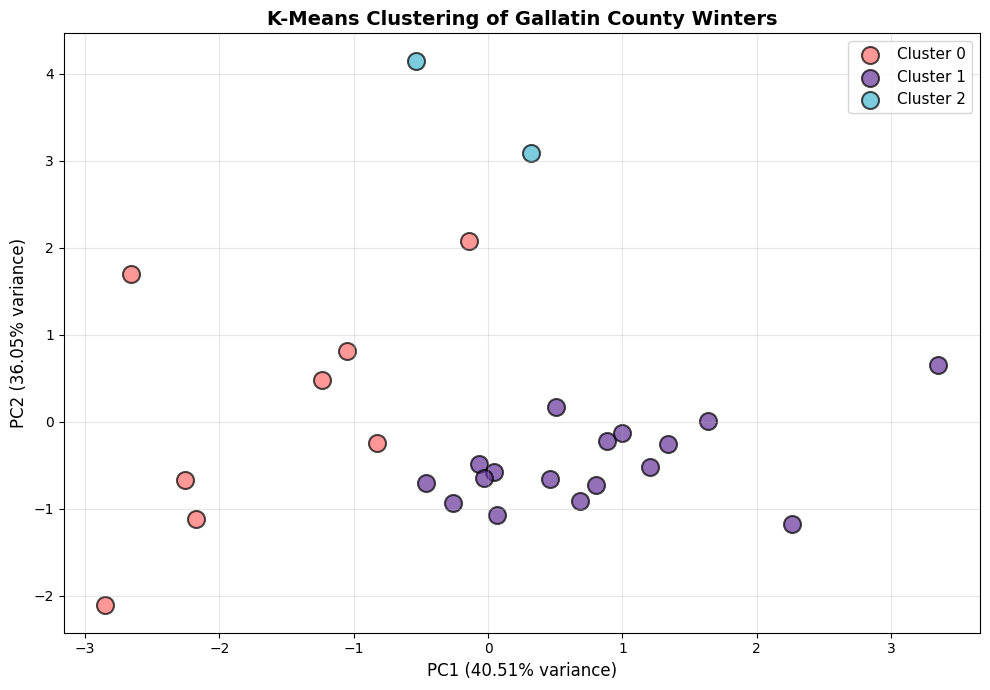


CLUSTER CHARACTERISTICS

Cluster 0 (8 winters):
  Avg Precipitation: 2.10"
  Avg Snowfall: 0.00"
  Avg Snow Depth: 1.92"
  Avg Max Temp: 32.1°F
  Avg Min Temp: 9.0°F
  All winters: 2000-2001, 2001-2002, 2002-2003, 2013-2014, 2016-2017, 2017-2018, 2018-2019, 2022-2023

Cluster 1 (17 winters):
  Avg Precipitation: 1.78"
  Avg Snowfall: 0.58"
  Avg Snow Depth: 0.07"
  Avg Max Temp: 39.3°F
  Avg Min Temp: 15.4°F
  All winters: 1999-2000, 2003-2004, 2004-2005, 2005-2006, 2006-2007, 2007-2008, 2008-2009, 2009-2010, 2010-2011, 2011-2012, 2012-2013, 2014-2015, 2015-2016, 2019-2020, 2020-2021, 2021-2022, 2025-2026

Cluster 2 (2 winters):
  Avg Precipitation: 2.71"
  Avg Snowfall: 47.00"
  Avg Snow Depth: 3.96"
  Avg Max Temp: 36.9°F
  Avg Min Temp: 14.0°F
  All winters: 2023-2024, 2024-2025


In [ ]:
#PREPARE FEATURES FOR K-MEANS
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

features = ['PRCP_total', 'SNOW_total', 'SNWD_avg', 'TMAX_avg', 'TMIN_avg']
X = winter_agg[features].copy()

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features ready for K-Means:")
print("Shape:", X_scaled.shape)
print("Features:", features)

# ELBOW METHOD & SILHOUETTE SCORE
inertias = []
silhouette_scores = []
k_values = range(2, 6)

for k in k_values:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans_temp.labels_))

# Plot results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_values, inertias, 'bo-', linewidth=2, markersize=8)
ax1.set_xlabel('Number of Clusters (k)', fontsize=12)
ax1.set_ylabel('Inertia', fontsize=12)
ax1.set_title('Elbow Method', fontsize=14, fontweight='bold')
ax1.grid(True, alpha=0.3)

ax2.plot(k_values, silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax2.set_xlabel('Number of Clusters (k)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.set_title('Silhouette Score by k', fontsize=14, fontweight='bold')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSilhouette Scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: {score:.4f}")

# FIT K-MEANS
optimal_k = 3  # Adjust based on your plots
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
winter_agg['Cluster'] = kmeans.fit_predict(X_scaled)

print(f"\nK-Means with k={optimal_k} fitted!")
print("\nCluster assignments by winter:")
print(winter_agg[['Winter_Year', 'Cluster', 'PRCP_total', 'SNOW_total', 'TMAX_avg']])

# VISUALIZE CLUSTERS
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
colors = ['#FF6B6B', '#663399', '#45B7D1']  # Dark purple
for cluster in range(optimal_k):
    mask = winter_agg['Cluster'] == cluster
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=colors[cluster], label=f'Cluster {cluster}',
                s=150, alpha=0.7, edgecolors='black', linewidth=1.5)

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)', fontsize=12)
plt.title('K-Means Clustering of Gallatin County Winters', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# DESCRIBE CLUSTERS WITH ALL WINTERS
print("\n" + "="*80)
print("CLUSTER CHARACTERISTICS")
print("="*80)

for cluster in range(optimal_k):
    cluster_data = winter_agg[winter_agg['Cluster'] == cluster]
    all_winters = ', '.join(cluster_data['Winter_Year'].tolist())

    print(f"\nCluster {cluster} ({len(cluster_data)} winters):")
    print(f"  Avg Precipitation: {cluster_data['PRCP_total'].mean():.2f}\"")
    print(f"  Avg Snowfall: {cluster_data['SNOW_total'].mean():.2f}\"")
    print(f"  Avg Snow Depth: {cluster_data['SNWD_avg'].mean():.2f}\"")
    print(f"  Avg Max Temp: {cluster_data['TMAX_avg'].mean():.1f}°F")
    print(f"  Avg Min Temp: {cluster_data['TMIN_avg'].mean():.1f}°F")
    print(f"  All winters: {all_winters}")

## Model 2: Random Forest Classification of the K-Means Clusters

The Random Forest learns to assign each winter to one of the three K-Means clusters using the same five features. Because the labels were created from these features, high accuracy here means the clusters are well separated. It does not mean the model can predict a future winter.

I used 5-fold cross-validation instead of a single 70/30 train/test split. With 27 winters, a 30% test set would contain only about 8 winters. Cross-validation tests each winter exactly once and averages accuracy across five folds, which gives a steadier estimate on a small dataset.

> **Note on cluster names:** the names in the code below were assigned before checking each cluster's averages, and they don't match the data. The cluster labeled "Dry & Warm" (cluster 0) is actually the coldest group, "Snowy & Wet" (cluster 1) is the mildest and driest, and "Cold & Dry" (cluster 2) is the two winters with high recorded snowfall. The code and outputs are left as originally run; the Results section uses names based on the actual cluster averages.

Cluster Distribution:
Cluster_Name
Snowy & Wet    17
Dry & Warm      8
Cold & Dry      2
Name: count, dtype: int64

All winters with cluster names:
Winter_Year  Cluster Cluster_Name  PRCP_total  SNOW_total  TMAX_avg
  1999-2000        1  Snowy & Wet        1.95         0.0 42.461538
  2000-2001        0   Dry & Warm        1.43         0.0 30.628099
  2001-2002        0   Dry & Warm        1.87         0.0 33.247934
  2002-2003        0   Dry & Warm        3.02         0.0 37.652893
  2003-2004        1  Snowy & Wet        1.81         0.0 36.860656
  2004-2005        1  Snowy & Wet        1.55         0.0 40.099174
  2005-2006        1  Snowy & Wet        1.93         0.0 36.000000
  2006-2007        1  Snowy & Wet        1.76         0.0 41.471074
  2007-2008        1  Snowy & Wet        1.33         0.0 38.532787
  2008-2009        1  Snowy & Wet        2.65         0.0 38.173554
  2009-2010        1  Snowy & Wet        1.42         0.0 35.719008
  2010-2011        1  Snowy & Wet   

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(



✓ Random Forest trained with 5-Fold Cross-Validation!

RANDOM FOREST PERFORMANCE (5-FOLD CROSS-VALIDATION)

Cross-Validation Scores: [0.83333333 0.83333333 0.8        0.8        1.        ]
Mean CV Accuracy: 0.8533 (+/- 0.0748)

Classification Report (Cross-Validation):
              precision    recall  f1-score   support

  Cold & Dry       0.00      0.00      0.00         2
  Dry & Warm       0.86      0.75      0.80         8
 Snowy & Wet       0.89      1.00      0.94        17

    accuracy                           0.85        27
   macro avg       0.58      0.58      0.58        27
weighted avg       0.82      0.85      0.83        27


Confusion Matrix:
[[ 0  1  1]
 [ 1  6  1]
 [ 0  0 17]]


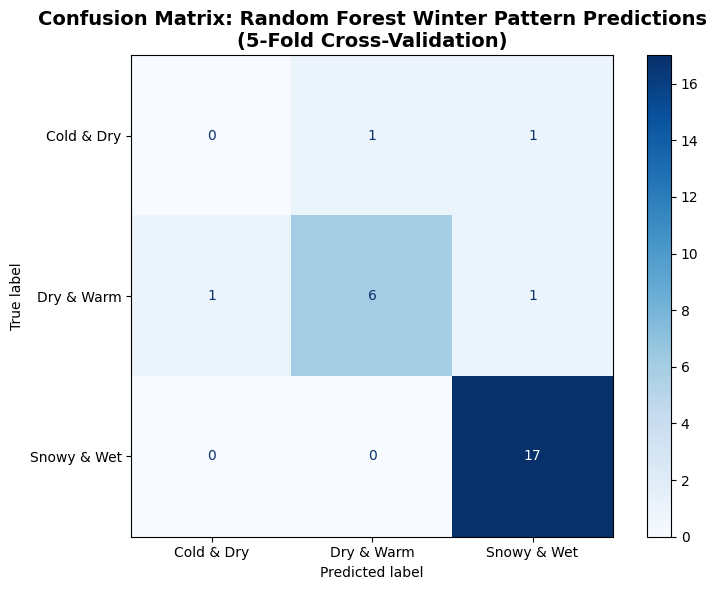


FEATURE IMPORTANCE
   Feature  Importance
  TMIN_avg    0.327263
  TMAX_avg    0.284551
  SNWD_avg    0.180828
PRCP_total    0.110287
SNOW_total    0.097071


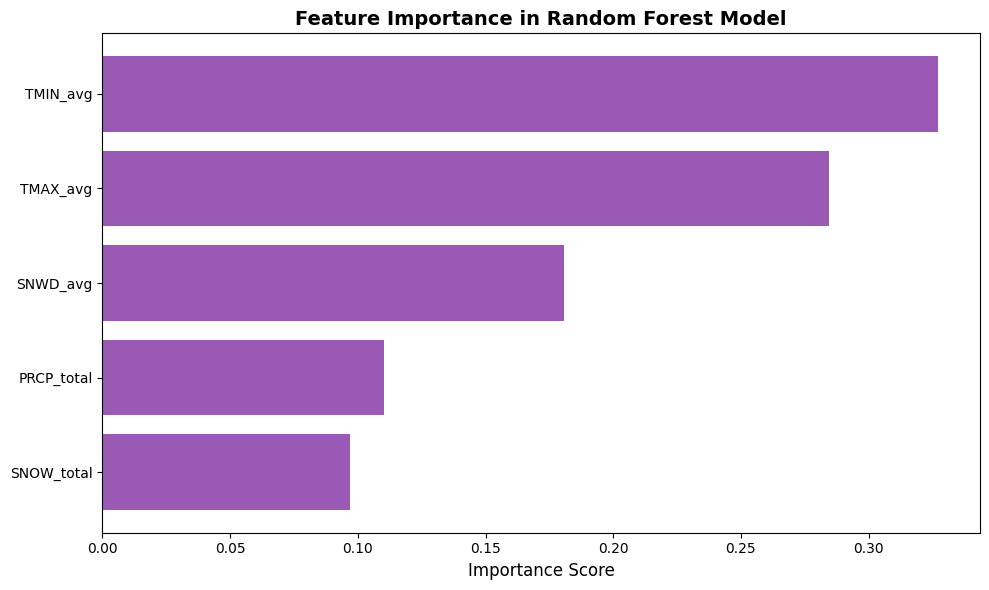


SUMMARY
Total winters evaluated: 27
Mean accuracy across 5 folds: 0.8533


In [ ]:

cluster_names = {
    0: 'Dry & Warm',
    1: 'Snowy & Wet',
    2: 'Cold & Dry'
}

winter_agg['Cluster_Name'] = winter_agg['Cluster'].map(cluster_names)

print("Cluster Distribution:")
print(winter_agg['Cluster_Name'].value_counts())

print("\nAll winters with cluster names:")
print(winter_agg[['Winter_Year', 'Cluster', 'Cluster_Name', 'PRCP_total', 'SNOW_total', 'TMAX_avg']].to_string(index=False))

# STEP 13: PREPARE DATA FOR RANDOM FOREST
from sklearn.model_selection import cross_val_score, cross_validate
from sklearn.metrics import accuracy_score, classification_report

features = ['PRCP_total', 'SNOW_total', 'SNWD_avg', 'TMAX_avg', 'TMIN_avg']
X = winter_agg[features].copy()
y = winter_agg['Cluster_Name'].copy()

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Random Forest Training Data:")
print(f"Features shape: {X_scaled.shape}")
print(f"Target distribution:\n{y.value_counts()}")

# STEP 14: TRAIN RANDOM FOREST WITH CROSS-VALIDATION =====
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=3,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Use 5-fold cross-validation
from sklearn.model_selection import cross_val_predict

cv_scores = cross_val_score(rf_model, X_scaled, y, cv=5, scoring='accuracy')
y_pred_cv = cross_val_predict(rf_model, X_scaled, y, cv=5)

print(f"\n✓ Random Forest trained with 5-Fold Cross-Validation!")

# STEP 15: EVALUATE MODEL
print("\n" + "="*80)
print("RANDOM FOREST PERFORMANCE (5-FOLD CROSS-VALIDATION)")
print("="*80)

print(f"\nCross-Validation Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

print("\nClassification Report (Cross-Validation):")
print(classification_report(y, y_pred_cv))

# STEP 16: CONFUSION MATRIX
all_classes = ['Cold & Dry', 'Dry & Warm', 'Snowy & Wet']
cm = confusion_matrix(y, y_pred_cv, labels=all_classes)
print("\nConfusion Matrix:")
print(cm)

# STEP 17: VISUALIZE CONFUSION MATRIX
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm, display_labels=all_classes).plot(ax=ax, cmap='Blues')
plt.title('Confusion Matrix: Random Forest Winter Pattern Predictions\n(5-Fold Cross-Validation)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# STEP 18: FEATURE IMPORTANCE
# Train on full dataset to get feature importance
rf_model.fit(X_scaled, y)

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n" + "="*80)
print("FEATURE IMPORTANCE")
print("="*80)
print(feature_importance.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(feature_importance['Feature'], feature_importance['Importance'], color='#9B59B6')
ax.set_xlabel('Importance Score', fontsize=12)
ax.set_title('Feature Importance in Random Forest Model', fontsize=14, fontweight='bold')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# STEP 19: SUMMARY
print("\n" + "="*80)
print("SUMMARY")
print("="*80)
print(f"Total winters evaluated: {len(y)}")
print(f"Mean accuracy across 5 folds: {cv_scores.mean():.4f}")

## Results

### K-Means Clustering

Silhouette scores were similar across k = 2 (0.440), k = 3 (0.405), and k = 4 (0.432), and lower for k = 5 (0.305). No value of k stood out clearly, which suggests the winters don't fall into sharply separated groups. I chose k = 3 for interpretability.

Based on the cluster averages:

| Cluster | Name in code | Descriptive name | Winters | Avg max temp | Avg min temp | Precip total | Recorded snowfall | Avg snow depth |
|---|---|---|---|---|---|---|---|---|
| 0 | Dry & Warm | Cold winters | 8 | 32.1°F | 9.0°F | 2.10" | 0.00" | 1.92" |
| 1 | Snowy & Wet | Mild, dry winters | 17 | 39.3°F | 15.4°F | 1.78" | 0.58" | 0.07" |
| 2 | Cold & Dry | High recorded snowfall | 2 | 36.9°F | 14.0°F | 2.71" | 47.00" | 3.96" |

- **Cluster 0 (cold winters):** 2000–01, 2001–02, 2002–03, 2013–14, 2016–17, 2017–18, 2018–19, and 2022–23. These are the coldest winters in the record. They show zero recorded snowfall but some recorded snow depth, which points to inconsistent snow reporting rather than a real weather pattern.
- **Cluster 1 (mild, dry winters):** the largest group, with the warmest temperatures and lowest precipitation. It includes the partial 1999–2000 winter and 2025–26.
- **Cluster 2 (high recorded snowfall):** only 2023–24 and 2024–25. These are the only winters with substantial snowfall in the record (43.7" and 50.3"). Every other winter except 2025–26 (9.9") shows zero snowfall, so this cluster most likely reflects when snowfall reporting resumed at the station, not two unusually snowy winters.

Temperature is the most trustworthy signal in these clusters, since temperature data is nearly complete. The cold vs. mild split between clusters 0 and 1 is likely real; cluster 2 is mostly an artifact of missing data.

### Random Forest Classification

The Random Forest reached a mean cross-validated accuracy of 85.3% (± 7.5%), with fold scores from 80% to 100%, correctly assigning 23 of 27 winters. For comparison, always predicting the largest cluster would score 17/27, or 63%.

By cluster (using the descriptive names above):

- **Mild, dry winters (17):** precision 0.89, recall 1.00. All 17 were assigned correctly.
- **Cold winters (8):** precision 0.86, recall 0.75. Six of 8 were assigned correctly.
- **High recorded snowfall (2):** precision 0.00, recall 0.00. Neither winter was assigned correctly. With only two examples, at least one is always missing from training in each fold.

Macro-averaged F1 was 0.58, much lower than accuracy, because the model fails completely on the smallest cluster.

Feature importances: minimum temperature (0.33), maximum temperature (0.28), snow depth (0.18), precipitation (0.11), and snowfall (0.10). Temperature accounts for about 61% of the importance, consistent with temperature being the most complete and reliable variable in this dataset.

## Limitations and Known Issues

**Missing snow data drives the clusters.** Snowfall is missing on about 88% of days and snow depth on about 84%, and missing values were treated as zero. Airport stations are largely automated, and snowfall is often not measured or only recorded when an observer reports it. As a result, 24 of 27 winters show zero total snowfall, and the high-snowfall cluster appears to capture a change in reporting rather than climate. A better approach would be to drop SNOW and SNWD, check each winter's data coverage before aggregating, or use a station that measures snowpack directly (such as an NRCS SNOTEL site).

**Cluster names were mismatched.** The names were assigned in code before checking the cluster averages, so the printed labels don't match the data (see the note above the Random Forest code). In future work, cluster names should be generated from the cluster averages so they can't be swapped.

**The Random Forest is circular.** It predicts K-Means labels from the same features K-Means used, so its accuracy shows how separable the clusters are, not whether winters can be predicted. Forecasting a future winter would require predictors known before the winter starts.

**Evaluation details.** The features were standardized on the full dataset before cross-validation; fitting the scaler inside each fold (for example, with a scikit-learn Pipeline) is the cleaner approach. Cross-validation folds were not shuffled, and the smallest cluster (2 winters) is too small for 5-fold stratification, which scikit-learn warns about in the output.

**Small, partial dataset.** There are only 27 winters, and the first (1999–2000) is missing December.

**Measurement quality.** Earlier years may reflect different equipment or reporting practices at the station, which could affect comparisons across the record.

## Next Steps

I'm rebuilding this idea as a true forecast: predicting the following spring's snowpack in the Bridger Range from conditions known before winter starts (the El Niño/La Niña index and fall SNOTEL data), with time-ordered validation and baseline comparisons.

## References

[1] National Oceanic and Atmospheric Administration (NOAA). "Global Historical Climatology Network-Daily (GHCN-Daily): Bozeman Gallatin Field Airport, MT (USW00024132)." National Centers for Environmental Information, https://www.ncdc.noaa.gov/cdo-web/. Accessed 21 June 2026.

[2] Felsche, E., and Ludwig, R. "Applying machine learning for drought prediction in a perfect model framework using data from a large ensemble of climate simulations." *Natural Hazards and Earth System Sciences*, vol. 21, 2021, pp. 3679–3691. https://doi.org/10.5194/nhess-21-3679-2021